In [47]:
%pip -q install pandas matplotlib seaborn scikit-learn

print('Installation cell finished. If prompted, restart the runtime, then choose Runtime > Run all.')


Installation cell finished. If prompted, restart the runtime, then choose Runtime > Run all.


In [48]:

!pip install --no-cache-dir scikit-surprise


In [49]:
# Imports and reproducibility
import io
import zipfile
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.base import BaseEstimator, RegressorMixin

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", None)
warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


In [50]:
#  Download and load MovieLens 100K
# u.data columns: user_id, item_id, rating, timestamp (tab-separated)
ratings_url = "https://files.grouplens.org/datasets/movielens/ml-100k/u.data"
movies_url = "https://files.grouplens.org/datasets/movielens/ml-100k/u.item"

ratings = pd.read_csv(
    ratings_url, sep="\\t", header=None,
    names=["user_id", "item_id", "rating", "timestamp"],
    engine="python"
)
movies = pd.read_csv(
    movies_url, sep="|", header=None, encoding="latin-1",
    usecols=[0, 1], names=["item_id", "title"]
)

print("Ratings shape:", ratings.shape)
print("Movies shape:", movies.shape)
display(ratings.head())
display(movies.head())

Ratings shape: (100000, 4)
Movies shape: (1682, 2)


,user_id,item_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


,item_id,title
0,1,Toy Story (1995)
1,2,GoldenEye (1995)
2,3,Four Rooms (1995)
3,4,Get Shorty (1995)
4,5,Copycat (1995)


In [51]:
# Data quality checks and preprocessing
print("Missing values before cleaning:\\n", ratings.isna().sum())
print("Duplicate rows before cleaning:", ratings.duplicated().sum())

ratings = ratings.drop_duplicates().dropna(subset=["user_id", "item_id", "rating"]).copy()
ratings["user_id"] = ratings["user_id"].astype(int)
ratings["item_id"] = ratings["item_id"].astype(int)
ratings["rating"] = ratings["rating"].astype(float)

# Validate the expected 1-to-5 rating range
ratings = ratings[ratings["rating"].between(1, 5)].copy()

print("\\nMissing values after cleaning:\\n", ratings.isna().sum())
print("Duplicate rows after cleaning:", ratings.duplicated().sum())
print("Cleaned ratings shape:", ratings.shape)
print("Unique users:", ratings["user_id"].nunique())
print("Unique movies:", ratings["item_id"].nunique())
print("Rating range:", ratings["rating"].min(), "to", ratings["rating"].max())

Missing values before cleaning:\n user_id      0
item_id      0
rating       0
timestamp    0
dtype: int64
Duplicate rows before cleaning: 0
\nMissing values after cleaning:\n user_id      0
item_id      0
rating       0
timestamp    0
dtype: int64
Duplicate rows after cleaning: 0
Cleaned ratings shape: (100000, 4)
Unique users: 943
Unique movies: 1682
Rating range: 1.0 to 5.0


In [52]:
from surprise import Dataset, Reader

,rating_summary
count,100000.000000
mean,3.529860
std,1.125674
min,1.000000
25%,3.000000
50%,4.000000
75%,4.000000
max,5.000000


Ratings per user (summary):


,ratings_per_user
count,943.000000
mean,106.044539
std,100.931743
min,20.000000
25%,33.000000
50%,65.000000
75%,148.000000
max,737.000000


Ratings per movie (summary):


,ratings_per_movie
count,1682.000000
mean,59.453032
std,80.383846
min,1.000000
25%,6.000000
50%,27.000000
75%,80.000000
max,583.000000


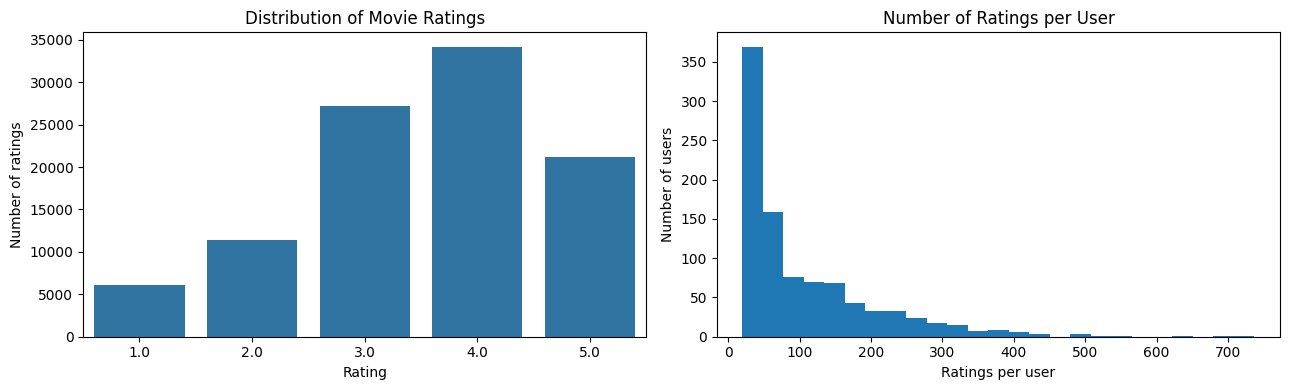

,item_id,rating_count,mean_rating,title
49,50,583,4.358491,Star Wars (1977)
257,258,509,3.803536,Contact (1997)
99,100,508,4.155512,Fargo (1996)
180,181,507,4.007890,Return of the Jedi (1983)
293,294,485,3.156701,Liar Liar (1997)
285,286,481,3.656965,"English Patient, The (1996)"
287,288,478,3.441423,Scream (1996)
0,1,452,3.878319,Toy Story (1995)
299,300,431,3.631090,Air Force One (1997)
120,121,429,3.438228,Independence Day (ID4) (1996)


In [53]:
#  Exploratory data analysis (EDA)
display(ratings["rating"].describe().to_frame("rating_summary"))
print("Ratings per user (summary):")
display(ratings.groupby("user_id").size().describe().to_frame("ratings_per_user"))
print("Ratings per movie (summary):")
display(ratings.groupby("item_id").size().describe().to_frame("ratings_per_movie"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=ratings, x="rating", ax=axes[0])
axes[0].set_title("Distribution of Movie Ratings")
axes[0].set_xlabel("Rating")
axes[0].set_ylabel("Number of ratings")

user_counts = ratings.groupby("user_id").size()
axes[1].hist(user_counts, bins=25)
axes[1].set_title("Number of Ratings per User")
axes[1].set_xlabel("Ratings per user")
axes[1].set_ylabel("Number of users")
plt.tight_layout()
plt.show()

# Most frequently rated movies
popular = (ratings.groupby("item_id").agg(rating_count=("rating","size"),
                                          mean_rating=("rating","mean"))
           .merge(movies, on="item_id", how="left")
           .sort_values("rating_count", ascending=False))
display(popular.head(10))

In [54]:
# Data Splitting
from surprise.model_selection import train_test_split

# Define the rating scale
reader = Reader(rating_scale=(1, 5))

# Load the ratings DataFrame into Surprise
data = Dataset.load_from_df(
    ratings[['user_id', 'item_id', 'rating']],
    reader
)

# Split the dataset: 75% training and 25% testing
trainset, testset = train_test_split(
    data,
    test_size=0.25,
    random_state=42
)

print("Training and testing datasets created successfully!")
print("Training ratings:", trainset.n_ratings)
print("Testing ratings:", len(testset))

Training and testing datasets created successfully!
Training ratings: 75000
Testing ratings: 25000


In [55]:
# Model Selection
from surprise import SVD

# Initialize the SVD model
model = SVD()

# Train the model
model.fit(trainset)

print("SVD model trained successfully!")

SVD model trained successfully!


In [56]:
# Model Evaluation
from surprise import accuracy

# Generate predictions using the test dataset
predictions = model.test(testset)

# Calculate RMSE
rmse = accuracy.rmse(predictions)

print(f"Root Mean Squared Error: {rmse}")

RMSE: 0.9396
Root Mean Squared Error: 0.9395567173787086


In [57]:
from surprise import Dataset, Reader

# Define the rating scale
reader = Reader(rating_scale=(1, 5))

# Convert the ratings DataFrame into a Surprise dataset
data_surprise = Dataset.load_from_df(
    ratings[['user_id', 'item_id', 'rating']],
    reader
)

print("Surprise dataset created successfully!")

Surprise dataset created successfully!


In [58]:
# Hyperparameter Tuning
from surprise import SVD
from surprise.model_selection import GridSearchCV

# Define hyperparameter values
param_grid = {
    'n_factors': [50, 100],
    'n_epochs': [20, 40],
    'lr_all': [0.002, 0.005]
}

# Perform grid search using 3-fold cross-validation
grid_search = GridSearchCV(
    SVD,
    param_grid,
    measures=['rmse'],
    cv=3
)

grid_search.fit(data_surprise)

# Display the best hyperparameters and RMSE
print("Best RMSE:", grid_search.best_score['rmse'])
print("Best Parameters:", grid_search.best_params['rmse'])

Best RMSE: 0.9414025512016808
Best Parameters: {'n_factors': 50, 'n_epochs': 20, 'lr_all': 0.005}


In [59]:
# Top N Recommendations
# Get the best SVD model from GridSearchCV
best_svd = grid_search.best_estimator['rmse']

# Train the model using the training dataset
best_svd.fit(trainset)

# Generate predictions for the test dataset
predictions = best_svd.test(testset)


def get_top_n(predictions, n=10):

    top_n = {}

    for uid, iid, true_r, est, _ in predictions:
        if uid not in top_n:
            top_n[uid] = []

        top_n[uid].append((iid, est))

    for uid, user_ratings in top_n.items():
        user_ratings.sort(key=lambda x: x[1], reverse=True)
        top_n[uid] = user_ratings[:n]

    return top_n


top_n_recommendations = get_top_n(predictions, n=10)

for user_id, recommendations in list(top_n_recommendations.items())[:5]:
    print(f"\nRecommendations for User {user_id}:")
    for movie_id, predicted_rating in recommendations:
        print(f"Movie ID: {movie_id}, Predicted Rating: {predicted_rating:.2f}")


Recommendations for User 391:
Movie ID: 427, Predicted Rating: 4.36
Movie ID: 318, Predicted Rating: 4.35
Movie ID: 12, Predicted Rating: 4.26
Movie ID: 480, Predicted Rating: 4.25
Movie ID: 180, Predicted Rating: 4.19
Movie ID: 59, Predicted Rating: 4.18
Movie ID: 479, Predicted Rating: 4.13
Movie ID: 646, Predicted Rating: 4.13
Movie ID: 134, Predicted Rating: 4.12
Movie ID: 648, Predicted Rating: 4.11

Recommendations for User 181:
Movie ID: 1, Predicted Rating: 2.52
Movie ID: 117, Predicted Rating: 2.40
Movie ID: 121, Predicted Rating: 2.34
Movie ID: 302, Predicted Rating: 2.29
Movie ID: 251, Predicted Rating: 2.28
Movie ID: 304, Predicted Rating: 2.28
Movie ID: 285, Predicted Rating: 2.25
Movie ID: 237, Predicted Rating: 2.24
Movie ID: 125, Predicted Rating: 2.24
Movie ID: 273, Predicted Rating: 2.18

Recommendations for User 637:
Movie ID: 285, Predicted Rating: 3.56
Movie ID: 127, Predicted Rating: 3.45
Movie ID: 475, Predicted Rating: 3.07
Movie ID: 282, Predicted Rating: 2.96